In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

# Load the dataset
file_path = '/IBM-HR-Employee-Attrition-selected-columns.csv'
df = pd.read_csv(file_path)

# Separate Target (y) and Features (X)
# 'Attrition' is our target classification column (Yes/No)
y = df['Attrition'].map({'Yes': 1, 'No': 0})
X = df.drop(columns=['Attrition'])

# Identify feature types automatically
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Features selected for training:")
print(f"Categorical features ({len(categorical_cols)}): {categorical_cols}")
print(f"Numerical features ({len(numerical_cols)}): {numerical_cols}\n")

# Create preprocessing transformers
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_cols)
    ]
)

# Create a processing and training pipeline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# 6. Train-test split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Fit the model
model_pipeline.fit(X_train, y_train)

# Predict and extract probabilities
y_pred = model_pipeline.predict(X_test)
y_pred_proba = model_pipeline.predict_proba(X_test)[:, 1]

# Calculate and print performance metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("=== Model Evaluation Metrics ===")
print(f"Precision (Positive Class: Attrition): {precision:.4f}")
print(f"Recall (Sensitivity):                 {recall:.4f}")
print(f"F1-Score:                             {f1:.4f}")
print(f"ROC-AUC Score:                        {roc_auc:.4f}\n")

print("Detailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=['No Attrition', 'Attrition']))

Features selected for training:
Categorical features (3): ['BusinessTravel', 'Department', 'EducationField']
Numerical features (6): ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber']

=== Model Evaluation Metrics ===
Precision (Positive Class: Attrition): 0.6667
Recall (Sensitivity):                 0.0426
F1-Score:                             0.0800
ROC-AUC Score:                        0.5687

Detailed Classification Report:
              precision    recall  f1-score   support

No Attrition       0.85      1.00      0.91       247
   Attrition       0.67      0.04      0.08        47

    accuracy                           0.84       294
   macro avg       0.76      0.52      0.50       294
weighted avg       0.82      0.84      0.78       294



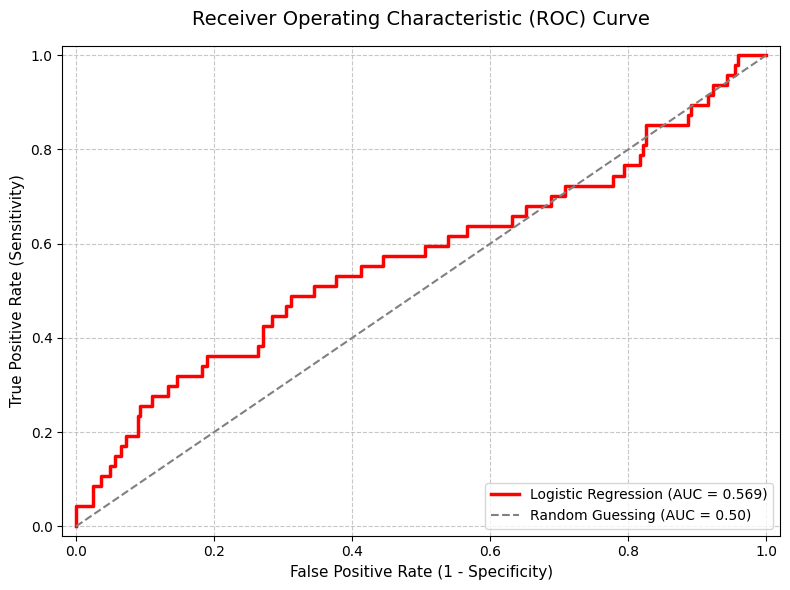

In [8]:
# Visualize the ROC Curve with high-contrast, clean styling
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

fig = plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='red', lw=2.5, label=f'Logistic Regression (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Random Guessing (AUC = 0.50)')

plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14, pad=15)
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=11)
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()